# Day 2: Train YOLO on a COCO Subset

Goal: train a YOLO detector, understand the YOLO annotation format, visually check labels before training, and evaluate the detector using mAP.



Install and import libraries

In [1]:
!pip -q install -U ultralytics

In [2]:
import os
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

import torch
import yaml
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cpu
CUDA available: False


Download the COCO128 dataset

In [3]:
# Ultralytics downloads COCO128 the first time this runs.
dataset_info = check_det_dataset("coco128.yaml")

print("Dataset location:", dataset_info["path"])
print("Training image directory from original YAML:", dataset_info["train"])
print("Validation image directory from original YAML:", dataset_info["val"])
print("Number of classes:", dataset_info["nc"])


WARNING ⚠️ Dataset 'coco128.yaml' images not found, missing path '/content/datasets/coco128/images/train2017'
Unzipping /content/datasets/coco128.zip to /content/datasets/coco128...: 100% ━━━━━━━━━━━━ 263/263 2.9Kfiles/s 0.1s
Dataset download success ✅ (0.6s), saved to /content/datasets

Dataset location: /content/datasets/coco128
Training image directory from original YAML: /content/datasets/coco128/images/train2017
Validation image directory from original YAML: /content/datasets/coco128/images/train2017
Number of classes: 80


Understand the YOLO annotation format

Each image has a matching `.txt` label file. Every object is represented by one line:

`class_id x_center y_center width height`

The four box values are normalized between 0 and 1 relative to the image width and height. The class ID is a zero-based integer. This differs from formats that store pixel coordinates such as `(x1, y1, x2, y2)`.

We will inspect the label files and draw a few boxes before training.

In [8]:
print("Image examples:")
print([p.name for p in image_paths[:10]])

print("\nLabel examples:")
print([p.name for p in list(source_labels.glob("*.txt"))[:10]])

print("\nTotal label files:", len(list(source_labels.glob("*.txt"))))

Image examples:
['000000000071.jpg', '000000000508.jpg', '000000000544.jpg', '000000000428.jpg', '000000000308.jpg', '000000000086.jpg', '000000000360.jpg', '000000000560.jpg', '000000000562.jpg', '000000000450.jpg']

Label examples:
['000000000328.txt', '000000000625.txt', '000000000294.txt', '000000000322.txt', '000000000636.txt', '000000000332.txt', '000000000144.txt', '000000000620.txt', '000000000283.txt', '000000000078.txt']

Total label files: 128


Create a reproducible train/validation split

In [9]:
# COCO128's YAML is intended as a tiny workflow/debugging dataset.
# We create our own separate image-level split to avoid evaluating on
# the same images used for training.

# Keep only images that have a matching annotation file
matched_images = [
    p for p in image_paths
    if (source_labels / f"{p.stem}.txt").exists()
]

print("Matched image-label pairs:", len(matched_images))

random.Random(SEED).shuffle(matched_images)

split_index = int(0.8 * len(matched_images))
train_images = matched_images[:split_index]
val_images = matched_images[split_index:]

split_root = Path("coco128_train_val_split")

for split_name, split_paths in [
    ("train", train_images),
    ("val", val_images)
]:
    image_out = split_root / "images" / split_name
    label_out = split_root / "labels" / split_name

    image_out.mkdir(parents=True, exist_ok=True)
    label_out.mkdir(parents=True, exist_ok=True)

    for image_path in split_paths:
        label_path = source_labels / f"{image_path.stem}.txt"

        shutil.copy2(image_path, image_out / image_path.name)
        shutil.copy2(label_path, label_out / label_path.name)

print("Training images:", len(train_images))
print("Validation images:", len(val_images))

Matched image-label pairs: 126
Training images: 100
Validation images: 26


Write a dataset YAML file for the split

In [10]:
# Keep the original COCO class names and IDs.
class_names = dataset_info["names"]
if isinstance(class_names, dict):
    names_for_yaml = [class_names[i] for i in range(len(class_names))]
else:
    names_for_yaml = list(class_names)

custom_yaml = {
    "path": str(split_root.resolve()),
    "train": "images/train",
    "val": "images/val",
    "nc": len(names_for_yaml),
    "names": names_for_yaml
}

yaml_path = Path("coco128_split.yaml")
with open(yaml_path, "w") as file:
    yaml.safe_dump(custom_yaml, file, sort_keys=False)

print(yaml_path.read_text())

path: /content/coco128_train_val_split
train: images/train
val: images/val
nc: 80
names:
- person
- bicycle
- car
- motorcycle
- airplane
- bus
- train
- truck
- boat
- traffic light
- fire hydrant
- stop sign
- parking meter
- bench
- bird
- cat
- dog
- horse
- sheep
- cow
- elephant
- bear
- zebra
- giraffe
- backpack
- umbrella
- handbag
- tie
- suitcase
- frisbee
- skis
- snowboard
- sports ball
- kite
- baseball bat
- baseball glove
- skateboard
- surfboard
- tennis racket
- bottle
- wine glass
- cup
- fork
- knife
- spoon
- bowl
- banana
- apple
- sandwich
- orange
- broccoli
- carrot
- hot dog
- pizza
- donut
- cake
- chair
- couch
- potted plant
- bed
- dining table
- toilet
- tv
- laptop
- mouse
- remote
- keyboard
- cell phone
- microwave
- oven
- toaster
- sink
- refrigerator
- book
- clock
- vase
- scissors
- teddy bear
- hair drier
- toothbrush



Visually validate a few annotations before training

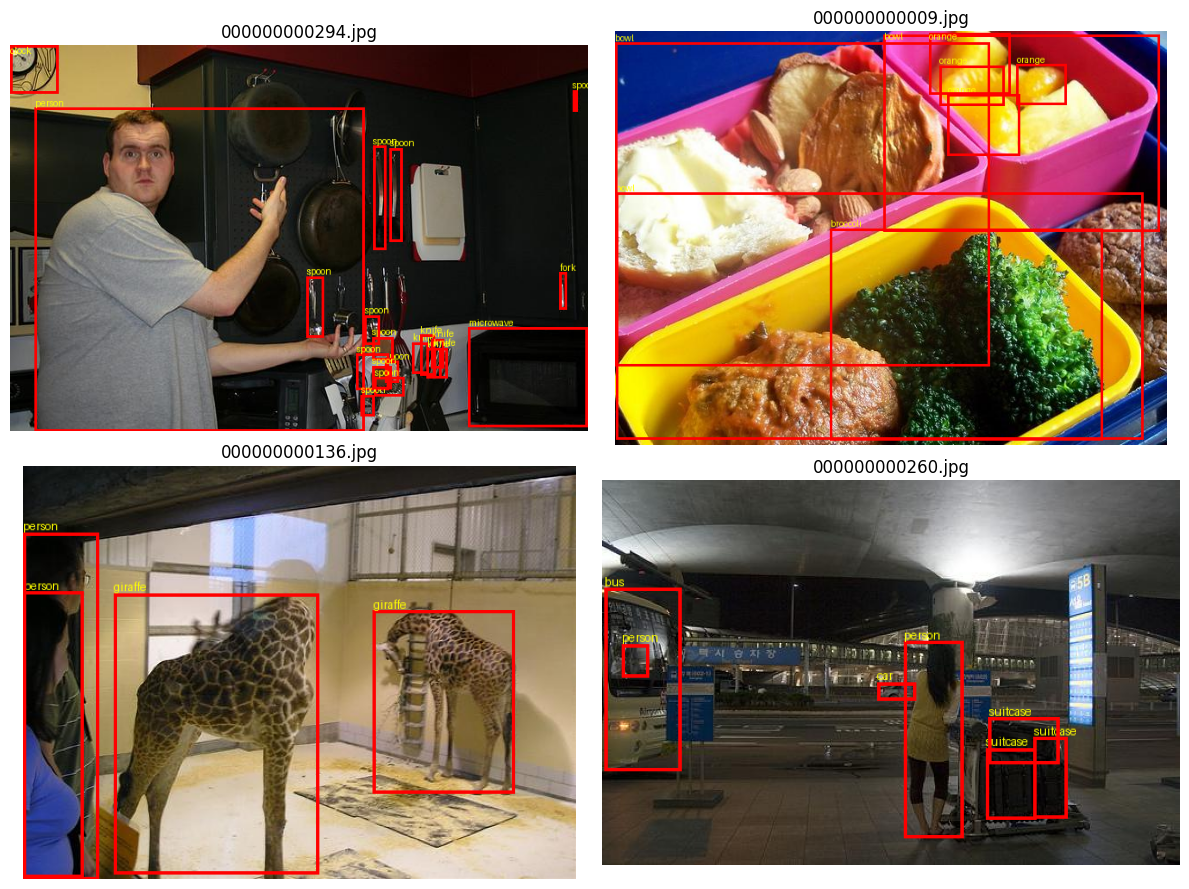

In [11]:
def draw_yolo_labels(image_path, label_path, class_names):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    image_width, image_height = image.size

    lines = label_path.read_text().strip().splitlines()
    for line in lines:
        values = line.split()
        class_id = int(values[0])
        x_center, y_center, box_width, box_height = map(float, values[1:5])

        x1 = (x_center - box_width / 2) * image_width
        y1 = (y_center - box_height / 2) * image_height
        x2 = (x_center + box_width / 2) * image_width
        y2 = (y_center + box_height / 2) * image_height

        draw.rectangle((x1, y1, x2, y2), outline="red", width=3)
        draw.text((x1, max(0, y1 - 12)), class_names[class_id], fill="yellow")

    return image

sample_paths = train_images[:4]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, image_path in zip(axes.flat, sample_paths):
    label_path = split_root / "labels" / "train" / f"{image_path.stem}.txt"
    ax.imshow(draw_yolo_labels(image_path, label_path, names_for_yaml))
    ax.set_title(image_path.name)
    ax.axis("off")
plt.tight_layout()
plt.show()

Check the displayed boxes before continuing. If boxes appear shifted, extremely large, missing, or unrelated to the objects, stop and inspect the label files. Incorrect annotations can make model training misleading.

Load a pretrained YOLO model

In [12]:
# YOLO11n is a small model, suitable for a first training exercise.
model = YOLO("yolo11n.pt")
print("Loaded YOLO11n pretrained weights.")

Loaded YOLO11n pretrained weights.


Train YOLO

In [13]:
# A short run is enough to practise the workflow on this tiny subset.
# Increase epochs later only if your runtime and dataset justify it.
train_results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=640,
    batch=8,
    patience=5,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=2,
    project="runs/module3",
    name="day2-yolo-coco128",
    exist_ok=True,
    plots=True,
    seed=SEED
)

Ultralytics 8.4.214 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco128_split.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=day2-yolo-coco128, nbs=64, nms=None, opset=None, optimize=False, opt

Evaluate using mAP

In [14]:
# Evaluate on the separate validation images created above.
metrics = model.val(
    data=str(yaml_path),
    split="val",
    imgsz=640,
    batch=8,
    device=0 if torch.cuda.is_available() else "cpu"
)

map50 = float(metrics.box.map50)
map50_95 = float(metrics.box.map)
map75 = float(metrics.box.map75)

print(f"mAP@0.50: {map50:.4f}")
print(f"mAP@0.50:0.95: {map50_95:.4f}")
print(f"mAP@0.75: {map75:.4f}")

Ultralytics 8.4.214 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1286.0±344.3 MB/s, size: 43.2 KB)
val: Scanning /content/coco128_train_val_split/labels/val.cache... 26 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 4.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.7s/it 6.8s
                   all         26        227      0.606      0.564      0.637      0.436
                person         13         76       0.64      0.776      0.752      0.496
                   car          2          5      0.279        0.2      0.195      0.176
            motorcycle          4          5      0.679          1      0.995       0.76
                 truck          2          6      0.708      0.416      0.752      0.516
         traffic light          1   

Save the evaluation results

In [15]:
results_table = pd.DataFrame([{
    "Model": "YOLO11n",
    "Dataset": "COCO128 (80/20 split)",
    "Epochs": 10,
    "mAP50": map50,
    "mAP50-95": map50_95,
    "mAP75": map75
}])

display(results_table)

results_dir = Path("module3_day2_results")
results_dir.mkdir(exist_ok=True)
results_table.to_csv(results_dir / "yolo_metrics.csv", index=False)
print("Saved:", results_dir / "yolo_metrics.csv")

,Model,Dataset,Epochs,mAP50,mAP50-95,mAP75
0,YOLO11n,COCO128 (80/20 split),10,0.636669,0.436032,0.501396


Saved: module3_day2_results/yolo_metrics.csv


Run inference on validation images

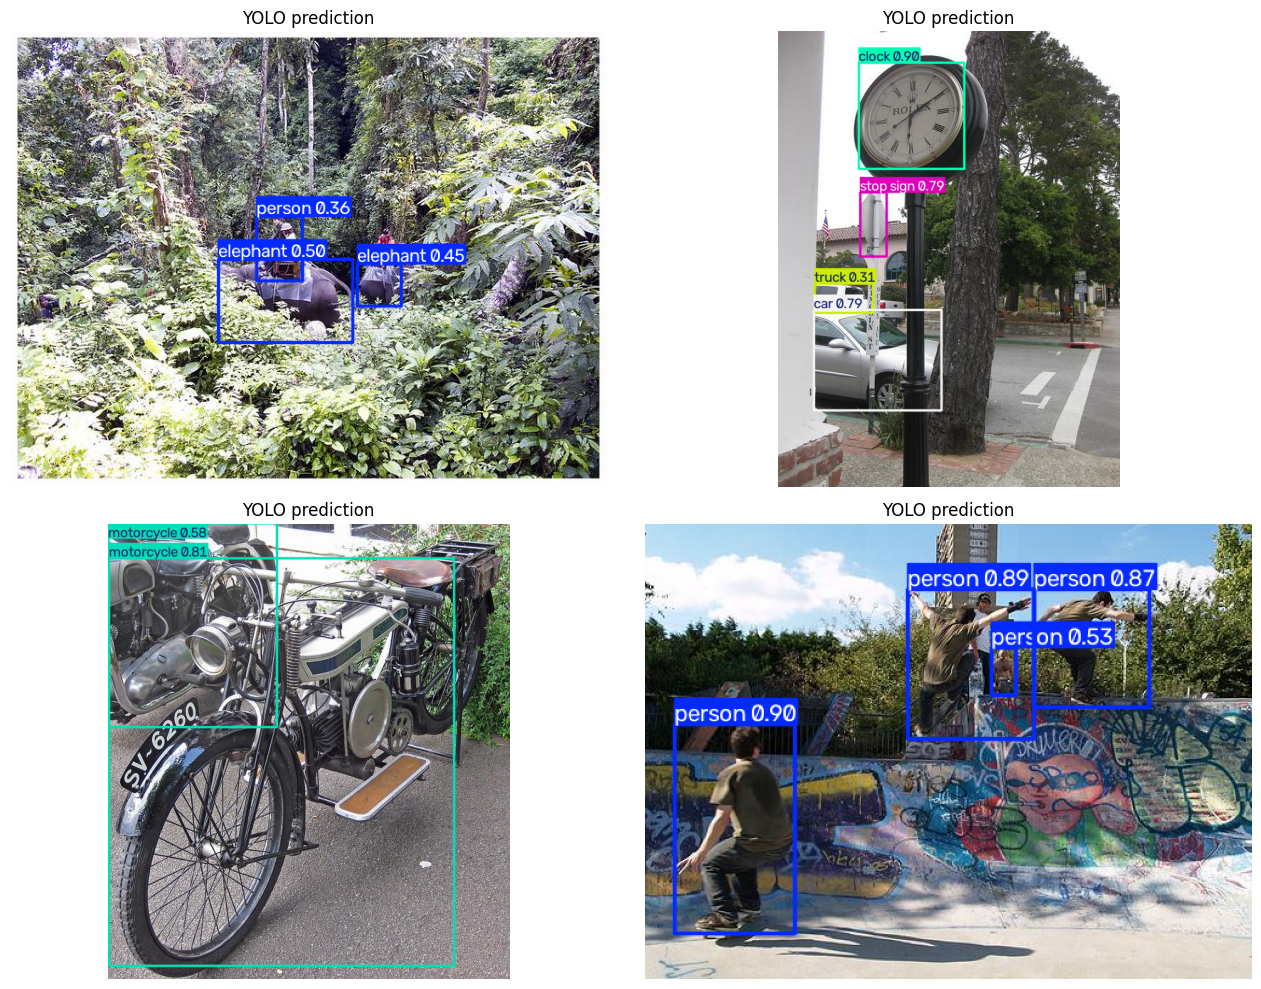

In [16]:
# Show a few predictions from images that were not used for training.
val_image_dir = split_root / "images" / "val"
val_image_paths = sorted(
    p for p in val_image_dir.iterdir()
    if p.suffix.lower() in image_extensions
)

prediction_results = model.predict(
    source=[str(p) for p in val_image_paths[:4]],
    conf=0.25,
    imgsz=640,
    device=0 if torch.cuda.is_available() else "cpu",
    verbose=False
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, prediction in zip(axes.flat, prediction_results):
    ax.imshow(prediction.plot()[..., ::-1])
    ax.axis("off")
    ax.set_title("YOLO prediction")
plt.tight_layout()
plt.show()